# ResNet-50 – Food-101 Image Classification

This project fine-tunes an ImageNet-pretrained ResNet-50 model to classify 101 types of food using the Food-101 benchmark. It uses staged transfer learning, a stratified validation split, image augmentation, mixed-precision training on CUDA, validation-based checkpoint selection, and an evaluation of the official test split. The notebook also examines class-wise performance, common confusions, sample predictions, and prediction confidence. The training setup is designed for Google Colab with an NVIDIA Tesla T4, although runtime depends on dataset download speed and available compute.

# 1. Import Libraries and Check Runtime

Load the deep learning, dataset, plotting, and evaluation libraries, then verify the available runtime.

In [1]:
import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.models import resnet50, ResNet50_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, precision_recall_fscore_support
from IPython.display import display

print(f"PyTorch: {torch.__version__}")
print(f"Torchvision: {__import__('torchvision').__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("GPU not detected. In Colab, select Runtime > Change runtime type > T4 GPU for faster training.")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4


# 2. Configure Reproducibility and Training

Set seeds, image dimensions, batch size, training stages, and output paths in one place.

In [2]:
SEED = 42
DATA_DIR = Path("food101_data")
CHECKPOINT_PATH = Path("resnet50_food101_best_224.pt")
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
VAL_SIZE = 5000
HEAD_EPOCHS = 3
FINE_TUNE_EPOCHS = 15
HEAD_LR = 1e-3
BACKBONE_LR = 1e-5
FINE_TUNE_HEAD_LR = 5e-5
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
USE_AMP = torch.cuda.is_available()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 101

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = torch.cuda.is_available()

generator = torch.Generator().manual_seed(SEED)
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError("A CUDA-enabled GPU is required for this experiment.")

print(f"Device: {DEVICE}")
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Image size: {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Head-training epochs: {HEAD_EPOCHS}")
print(f"Fine-tuning epochs: {FINE_TUNE_EPOCHS}")
print(f"Automatic mixed precision: {USE_AMP}")

Device: cuda
GPU: Tesla T4
Image size: 224 x 224
Batch size: 32
Head-training epochs: 3
Fine-tuning epochs: 15
Automatic mixed precision: True


# 3. Load the Food-101 Dataset

Download the official Food-101 training and test splits through Torchvision; the first download may take several minutes.

In [3]:
train_raw = datasets.Food101(root=str(DATA_DIR), split="train", download=True, transform=None)
test_raw = datasets.Food101(root=str(DATA_DIR), split="test", download=True, transform=None)

class_names = train_raw.classes
NUM_CLASSES = len(class_names)

print(f"Training split images: {len(train_raw):,}")
print(f"Official test images: {len(test_raw):,}")
print(f"Number of classes: {NUM_CLASSES}")
print(f"First ten classes: {class_names[:10]}")

100%|██████████| 5.00G/5.00G [03:20<00:00, 24.9MB/s]


Training split images: 75,750
Official test images: 25,250
Number of classes: 101
First ten classes: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']


# 4. Inspect the Dataset

Check class balance and visualize representative images before training.

,class,training_images
0,apple_pie,750
1,baby_back_ribs,750
2,baklava,750
3,beef_carpaccio,750
4,beef_tartare,750
5,beet_salad,750
6,beignets,750
7,bibimbap,750
8,bread_pudding,750
9,breakfast_burrito,750


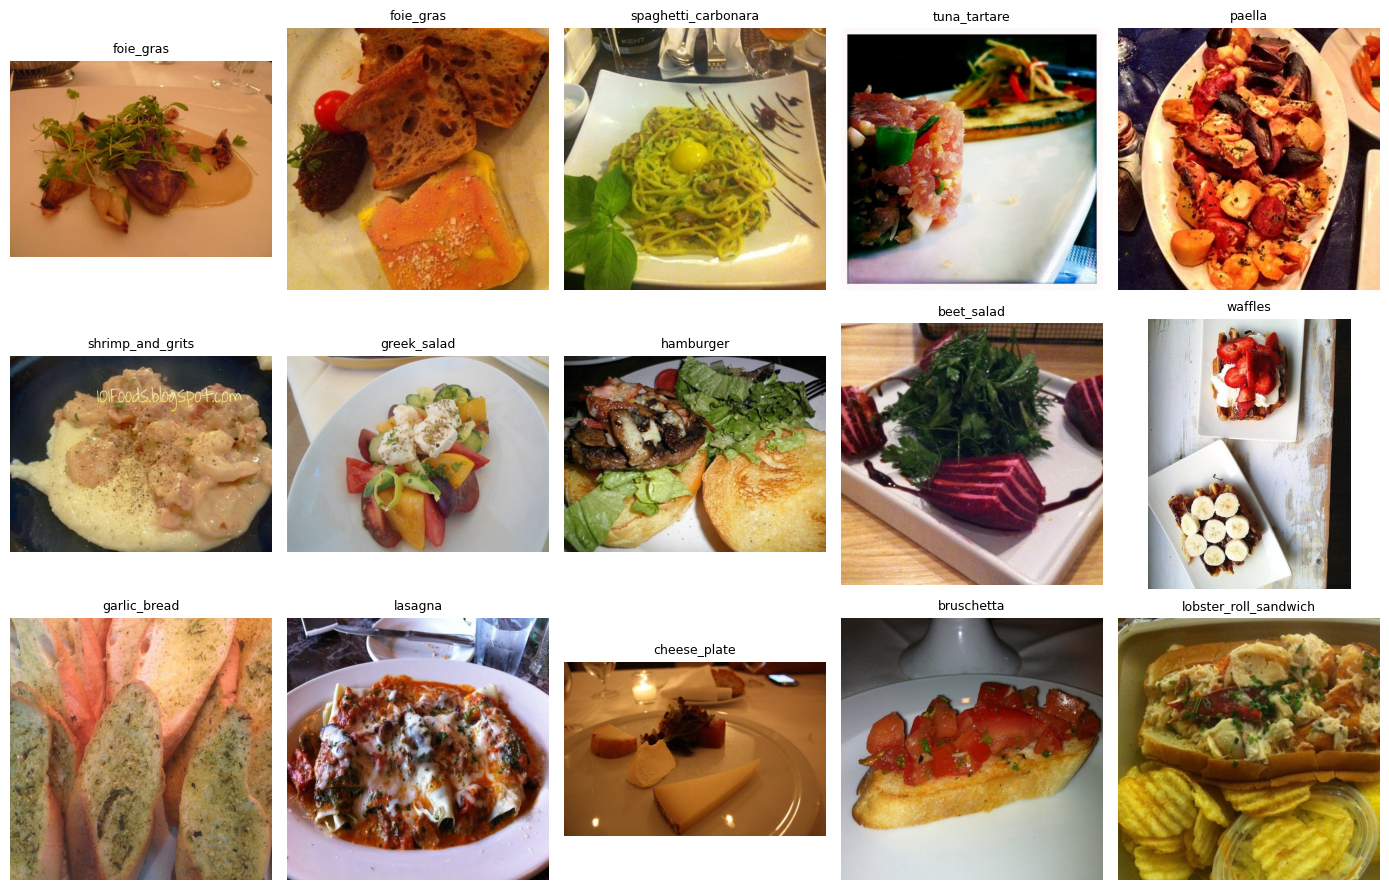

In [4]:
train_labels = np.asarray(train_raw._labels, dtype=np.int64)
class_counts = pd.Series(train_labels).value_counts().reindex(range(len(class_names)), fill_value=0).sort_index()
display(pd.DataFrame({"class": class_names, "training_images": class_counts.values}).head(12))

rng = np.random.default_rng(SEED)
example_indices = rng.choice(len(train_raw), size=15, replace=False)
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for ax, idx in zip(axes.flat, example_indices):
    image, label = train_raw[int(idx)]
    ax.imshow(image)
    ax.set_title(class_names[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


# 5. Create Training and Validation Splits

Reserve a stratified 5,000-image validation subset from the official training split and keep the official test split untouched until final evaluation.

In [5]:
all_train_indices = np.arange(len(train_raw))
train_indices, val_indices = train_test_split(
    all_train_indices,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=train_labels
)

print(f"Training images: {len(train_indices):,}")
print(f"Validation images: {len(val_indices):,}")
print(f"Official test images: {len(test_raw):,}")
print(f"Class mapping is consistent: {train_raw.class_to_idx == test_raw.class_to_idx}")


Training images: 70,750
Validation images: 5,000
Official test images: 25,250
Class mapping is consistent: True


# 6. Define Image Transforms

Use moderate training augmentation and deterministic ImageNet-compatible preprocessing for validation and test images.

In [6]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

EVAL_RESIZE = int(IMAGE_SIZE * 256 / 224)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandAugment(num_ops=2, magnitude=7),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.1, scale=(0.02, 0.12), value="random")
])

eval_transform = transforms.Compose([
    transforms.Resize(EVAL_RESIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print(f"Training image size: {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Evaluation resize: {EVAL_RESIZE}")
print("Training and evaluation transforms are ready.")

Training image size: 224 x 224
Evaluation resize: 256
Training and evaluation transforms are ready.


# 7. Build DataLoaders

Apply the appropriate transforms to each split and prepare shuffled training batches with pinned memory when CUDA is available.

In [7]:
class TransformedFoodSubset(Dataset):
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, label = self.base_dataset[int(self.indices[index])]
        if self.transform is not None:
            image = self.transform(image)
        return image, label

train_dataset = TransformedFoodSubset(train_raw, train_indices, train_transform)
val_dataset = TransformedFoodSubset(train_raw, val_indices, eval_transform)
test_dataset = TransformedFoodSubset(test_raw, np.arange(len(test_raw)), eval_transform)

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
    "persistent_workers": NUM_WORKERS > 0
}
train_loader = DataLoader(train_dataset, shuffle=True, generator=generator, **loader_options)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

print(f"Training batches per epoch: {len(train_loader):,}")
print(f"Validation batches: {len(val_loader):,}")
print(f"Test batches: {len(test_loader):,}")

Training batches per epoch: 2,211
Validation batches: 157
Test batches: 790


# 8. Load Pretrained ResNet-50

Initialize ResNet-50 with ImageNet-1K V2 pretrained weights and replace its final layer for 101 food categories.

In [8]:
weights = ResNet50_Weights.IMAGENET1K_V2
model = resnet50(weights=weights)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(DEVICE)

print("Loaded ImageNet-pretrained ResNet-50 and replaced the classification head.")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 148MB/s]


Loaded ImageNet-pretrained ResNet-50 and replaced the classification head.


# 9. Inspect Model Architecture

Review the classifier layer and parameter counts before starting transfer learning.

In [9]:
total_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(model.fc)
print(f"Total parameters: {total_parameters:,}")
print(f"Initially trainable parameters: {trainable_parameters:,}")

Linear(in_features=2048, out_features=101, bias=True)
Total parameters: 23,714,981
Initially trainable parameters: 23,714,981


# 10. Prepare Training Utilities

Define the epoch runner, compact epoch logging, cosine learning-rate scheduling, and validation-based checkpoint saving.

In [10]:
train_criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
eval_criterion = nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
history = []
best_val_accuracy = -1.0
best_epoch = None

def run_epoch(model, loader, criterion, optimizer=None, freeze_backbone=False):
    is_training = optimizer is not None
    model.train(is_training)
    if is_training and freeze_backbone:
        model.eval()
        model.fc.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, targets)

            if is_training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()

        running_loss += loss.detach().item() * images.size(0)
        correct += (logits.detach().argmax(dim=1) == targets).sum().item()
        total += targets.size(0)

    return running_loss / max(total, 1), correct / max(total, 1)


def fit_phase(phase_name, epochs, optimizer, freeze_backbone=False):
    global best_val_accuracy, best_epoch, history
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    for phase_epoch in range(1, epochs + 1):
        start_time = time.time()
        train_loss, train_accuracy = run_epoch(
            model, train_loader, train_criterion, optimizer=optimizer, freeze_backbone=freeze_backbone
        )
        val_loss, val_accuracy = run_epoch(model, val_loader, eval_criterion)
        scheduler.step()

        overall_epoch = len(history) + 1
        row = {
            "epoch": overall_epoch,
            "phase": phase_name,
            "phase_epoch": phase_epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "learning_rate": optimizer.param_groups[-1]["lr"],
            "seconds": time.time() - start_time
        }
        history.append(row)

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = overall_epoch
            torch.save({
                "model_state_dict": model.state_dict(),
                "best_val_accuracy": best_val_accuracy,
                "best_epoch": best_epoch,
                "best_phase": phase_name,
                "class_names": class_names
            }, CHECKPOINT_PATH)
            checkpoint_text = " | checkpoint saved"
        else:
            checkpoint_text = ""

        print(
            f"Epoch {overall_epoch:02d} | {phase_name} {phase_epoch}/{epochs} | "
            f"train loss {train_loss:.4f} | train acc {train_accuracy:.2%} | "
            f"val loss {val_loss:.4f} | val acc {val_accuracy:.2%} | "
            f"lr {optimizer.param_groups[-1]['lr']:.2e} | "
            f"{row['seconds'] / 60:.1f} min{checkpoint_text}"
        )

print(f"Checkpoint path: {CHECKPOINT_PATH.resolve()}")

Checkpoint path: /content/resnet50_food101_best_224.pt


# 11. Train the Classification Head

Freeze the pretrained feature extractor and train the new 101-class classifier for a short warm-up phase.

In [11]:
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.fc.parameters():
    parameter.requires_grad = True

head_optimizer = torch.optim.AdamW(model.fc.parameters(), lr=HEAD_LR, weight_decay=WEIGHT_DECAY)
fit_phase("Head", HEAD_EPOCHS, head_optimizer, freeze_backbone=True)

print(f"Best validation accuracy after head training: {best_val_accuracy:.2%}")

Epoch 01 | Head 1/3 | train loss 2.6375 | train acc 51.38% | val loss 1.6149 | val acc 62.42% | lr 7.50e-04 | 7.5 min | checkpoint saved
Epoch 02 | Head 2/3 | train loss 2.1315 | train acc 62.62% | val loss 1.4865 | val acc 64.86% | lr 2.50e-04 | 7.1 min | checkpoint saved
Epoch 03 | Head 3/3 | train loss 2.0245 | train acc 65.95% | val loss 1.4487 | val acc 66.28% | lr 0.00e+00 | 7.0 min | checkpoint saved
Best validation accuracy after head training: 66.28%


# 12. Fine-Tune ResNet-50

Unfreeze the full model and fine-tune its pretrained features with a lower backbone learning rate and a higher classifier learning rate.

In [12]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])

for parameter in model.parameters():
    parameter.requires_grad = True

backbone_parameters = [
    parameter
    for name, parameter in model.named_parameters()
    if not name.startswith("fc.")
]

fine_tune_optimizer = torch.optim.AdamW(
    [
        {"params": backbone_parameters, "lr": BACKBONE_LR},
        {"params": model.fc.parameters(), "lr": FINE_TUNE_HEAD_LR}
    ],
    weight_decay=WEIGHT_DECAY
)

fit_phase(
    "Fine-tune",
    FINE_TUNE_EPOCHS,
    fine_tune_optimizer,
    freeze_backbone=False
)

print(f"Best validation accuracy: {best_val_accuracy:.2%} at overall epoch {best_epoch}")

Epoch 04 | Fine-tune 1/15 | train loss 2.0822 | train acc 63.96% | val loss 1.1996 | val acc 70.80% | lr 4.95e-05 | 7.9 min | checkpoint saved
Epoch 05 | Fine-tune 2/15 | train loss 1.7932 | train acc 72.42% | val loss 1.0807 | val acc 74.18% | lr 4.78e-05 | 7.5 min | checkpoint saved
Epoch 06 | Fine-tune 3/15 | train loss 1.6925 | train acc 75.48% | val loss 1.0101 | val acc 75.80% | lr 4.52e-05 | 7.6 min | checkpoint saved
Epoch 07 | Fine-tune 4/15 | train loss 1.6187 | train acc 77.74% | val loss 0.9668 | val acc 76.74% | lr 4.17e-05 | 7.6 min | checkpoint saved
Epoch 08 | Fine-tune 5/15 | train loss 1.5610 | train acc 79.75% | val loss 0.9456 | val acc 77.52% | lr 3.75e-05 | 7.5 min | checkpoint saved
Epoch 09 | Fine-tune 6/15 | train loss 1.5171 | train acc 81.19% | val loss 0.9172 | val acc 78.24% | lr 3.27e-05 | 7.6 min | checkpoint saved
Epoch 10 | Fine-tune 7/15 | train loss 1.4823 | train acc 82.29% | val loss 0.9076 | val acc 78.22% | lr 2.76e-05 | 7.6 min
Epoch 11 | Fine-tu

# 13. Inspect Training History

Review the recorded epoch metrics to compare training and validation behavior across both training phases.

In [13]:
history_df = pd.DataFrame(history)
display(history_df.round({"train_loss": 4, "train_accuracy": 4, "val_loss": 4, "val_accuracy": 4, "learning_rate": 7, "seconds": 1}))
print(f"Completed epochs: {len(history_df)}")

,epoch,phase,phase_epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
0,1,Head,1,2.6375,0.5138,1.6149,0.6242,7.500000e-04,448.1
1,2,Head,2,2.1315,0.6262,1.4865,0.6486,2.500000e-04,428.8
2,3,Head,3,2.0245,0.6595,1.4487,0.6628,0.000000e+00,417.5
3,4,Fine-tune,1,2.0822,0.6396,1.1996,0.7080,4.950000e-05,471.1
4,5,Fine-tune,2,1.7932,0.7242,1.0807,0.7418,4.780000e-05,450.0
5,6,Fine-tune,3,1.6925,0.7548,1.0101,0.7580,4.520000e-05,454.6
6,7,Fine-tune,4,1.6187,0.7774,0.9668,0.7674,4.170000e-05,456.1
7,8,Fine-tune,5,1.5610,0.7975,0.9456,0.7752,3.750000e-05,452.9
8,9,Fine-tune,6,1.5171,0.8119,0.9172,0.7824,3.270000e-05,458.0
9,10,Fine-tune,7,1.4823,0.8229,0.9076,0.7822,2.760000e-05,453.4


Completed epochs: 18


# 14. Plot Training and Validation Metrics

Plot loss and accuracy by epoch to identify convergence, overfitting, and the best validation checkpoint.

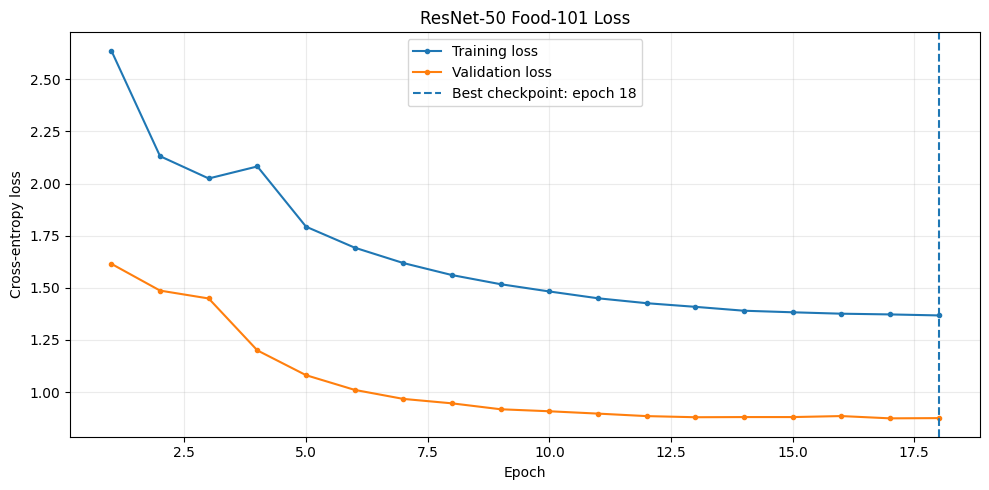

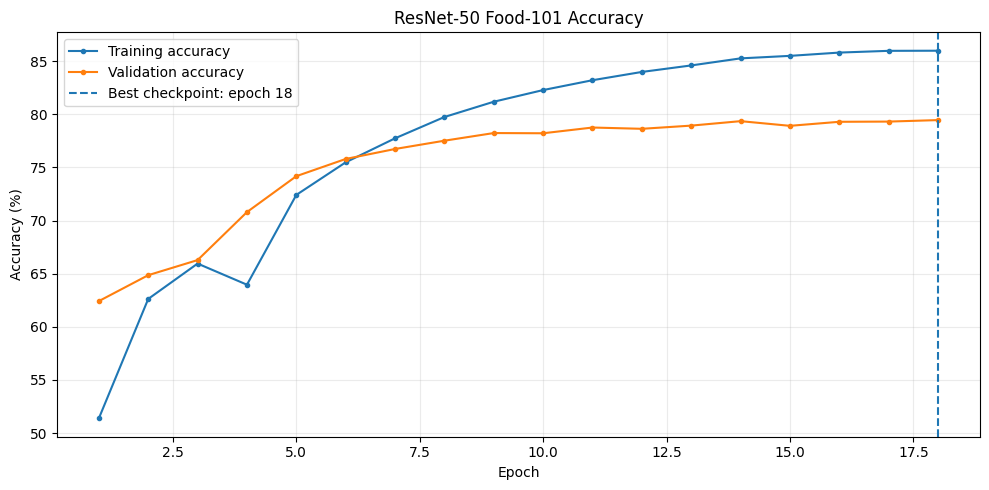

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", markersize=3, label="Training loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", markersize=3, label="Validation loss")
plt.axvline(best_epoch, linestyle="--", label=f"Best checkpoint: epoch {best_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("ResNet-50 Food-101 Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["train_accuracy"] * 100, marker="o", markersize=3, label="Training accuracy")
plt.plot(history_df["epoch"], history_df["val_accuracy"] * 100, marker="o", markersize=3, label="Validation accuracy")
plt.axvline(best_epoch, linestyle="--", label=f"Best checkpoint: epoch {best_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet-50 Food-101 Accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 15. Load the Best Checkpoint

Restore the model weights selected by validation accuracy before running final test evaluation.

In [15]:
best_checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print(f"Checkpoint phase: {best_checkpoint['best_phase']}")
print(f"Checkpoint epoch: {best_checkpoint['best_epoch']}")
print(f"Best validation accuracy: {best_checkpoint['best_val_accuracy']:.2%}")

Checkpoint phase: Fine-tune
Checkpoint epoch: 18
Best validation accuracy: 79.46%


# 16. Evaluate on the Test Set

Evaluate the selected checkpoint once on Food-101's official test split and store predictions for the remaining analyses.

In [16]:
model.eval()
test_loss_total = 0.0
test_targets = []
test_predictions = []
test_probabilities = []

with torch.inference_mode():
    for images, targets in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        targets_device = targets.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
            loss = eval_criterion(logits, targets_device)
        probabilities = torch.softmax(logits.float(), dim=1)
        test_loss_total += loss.item() * images.size(0)
        test_targets.append(targets.cpu().numpy())
        test_predictions.append(probabilities.argmax(dim=1).cpu().numpy())
        test_probabilities.append(probabilities.cpu().numpy())

y_test = np.concatenate(test_targets)
y_pred = np.concatenate(test_predictions)
test_probs = np.concatenate(test_probabilities)
test_loss = test_loss_total / len(test_dataset)

print(f"Test images evaluated: {len(y_test):,}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")

Test images evaluated: 25,250
Test loss: 0.7187
Test accuracy: 83.04%


# 17. Summarize Classification Metrics

Calculate overall test accuracy, macro and weighted precision/recall/F1, and the number of correct predictions.

In [17]:
test_metrics = {
    "Test Loss": test_loss,
    "Test Accuracy": accuracy_score(y_test, y_pred),
    "Macro Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    "Correct Predictions": int((y_test == y_pred).sum()),
    "Incorrect Predictions": int((y_test != y_pred).sum())
}

display(pd.DataFrame({"Metric": list(test_metrics.keys()), "Value": list(test_metrics.values())}))

,Metric,Value
0,Test Loss,0.718724
1,Test Accuracy,0.830416
2,Macro Precision,0.830554
3,Macro Recall,0.830416
4,Macro F1,0.829669
5,Weighted F1,0.829669
6,Correct Predictions,20968.000000
7,Incorrect Predictions,4282.000000


# 18. Analyze Class-wise Performance

Compare per-class precision, recall, F1-score, and support to identify categories that are easier or harder to recognize.

In [18]:
class_precision, class_recall, class_f1, class_support = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    zero_division=0
)
class_metrics = pd.DataFrame({
    "Class": class_names,
    "Precision": class_precision,
    "Recall": class_recall,
    "F1": class_f1,
    "Support": class_support
})

print("Ten strongest classes by F1-score")
display(class_metrics.sort_values("F1", ascending=False).head(10).round(4))
print("Ten most challenging classes by F1-score")
display(class_metrics.sort_values("F1", ascending=True).head(10).round(4))

Ten strongest classes by F1-score


,Class,Precision,Recall,F1,Support
33,edamame,0.9920,0.996,0.9940,250
63,macarons,0.9837,0.968,0.9758,250
69,oysters,0.9549,0.932,0.9433,250
65,mussels,0.9544,0.920,0.9369,250
54,hot_and_sour_soup,0.9189,0.952,0.9352,250
97,takoyaki,0.9255,0.944,0.9347,250
91,spaghetti_carbonara,0.9122,0.956,0.9336,250
30,deviled_eggs,0.9429,0.924,0.9333,250
64,miso_soup,0.9390,0.924,0.9315,250
88,seaweed_salad,0.9283,0.932,0.9301,250


Ten most challenging classes by F1-score


,Class,Precision,Recall,F1,Support
93,steak,0.5665,0.528,0.5466,250
77,pork_chop,0.6261,0.556,0.5890,250
37,filet_mignon,0.6064,0.684,0.6429,250
56,huevos_rancheros,0.6681,0.628,0.6474,250
39,foie_gras,0.7241,0.588,0.6490,250
8,bread_pudding,0.6920,0.620,0.6540,250
0,apple_pie,0.6653,0.660,0.6627,250
22,chocolate_mousse,0.6593,0.712,0.6846,250
82,ravioli,0.7318,0.644,0.6851,250
15,ceviche,0.7454,0.644,0.6910,250


# 19. Plot the Confusion Matrix

Visualize class confusions across the 101 categories using the official test predictions.

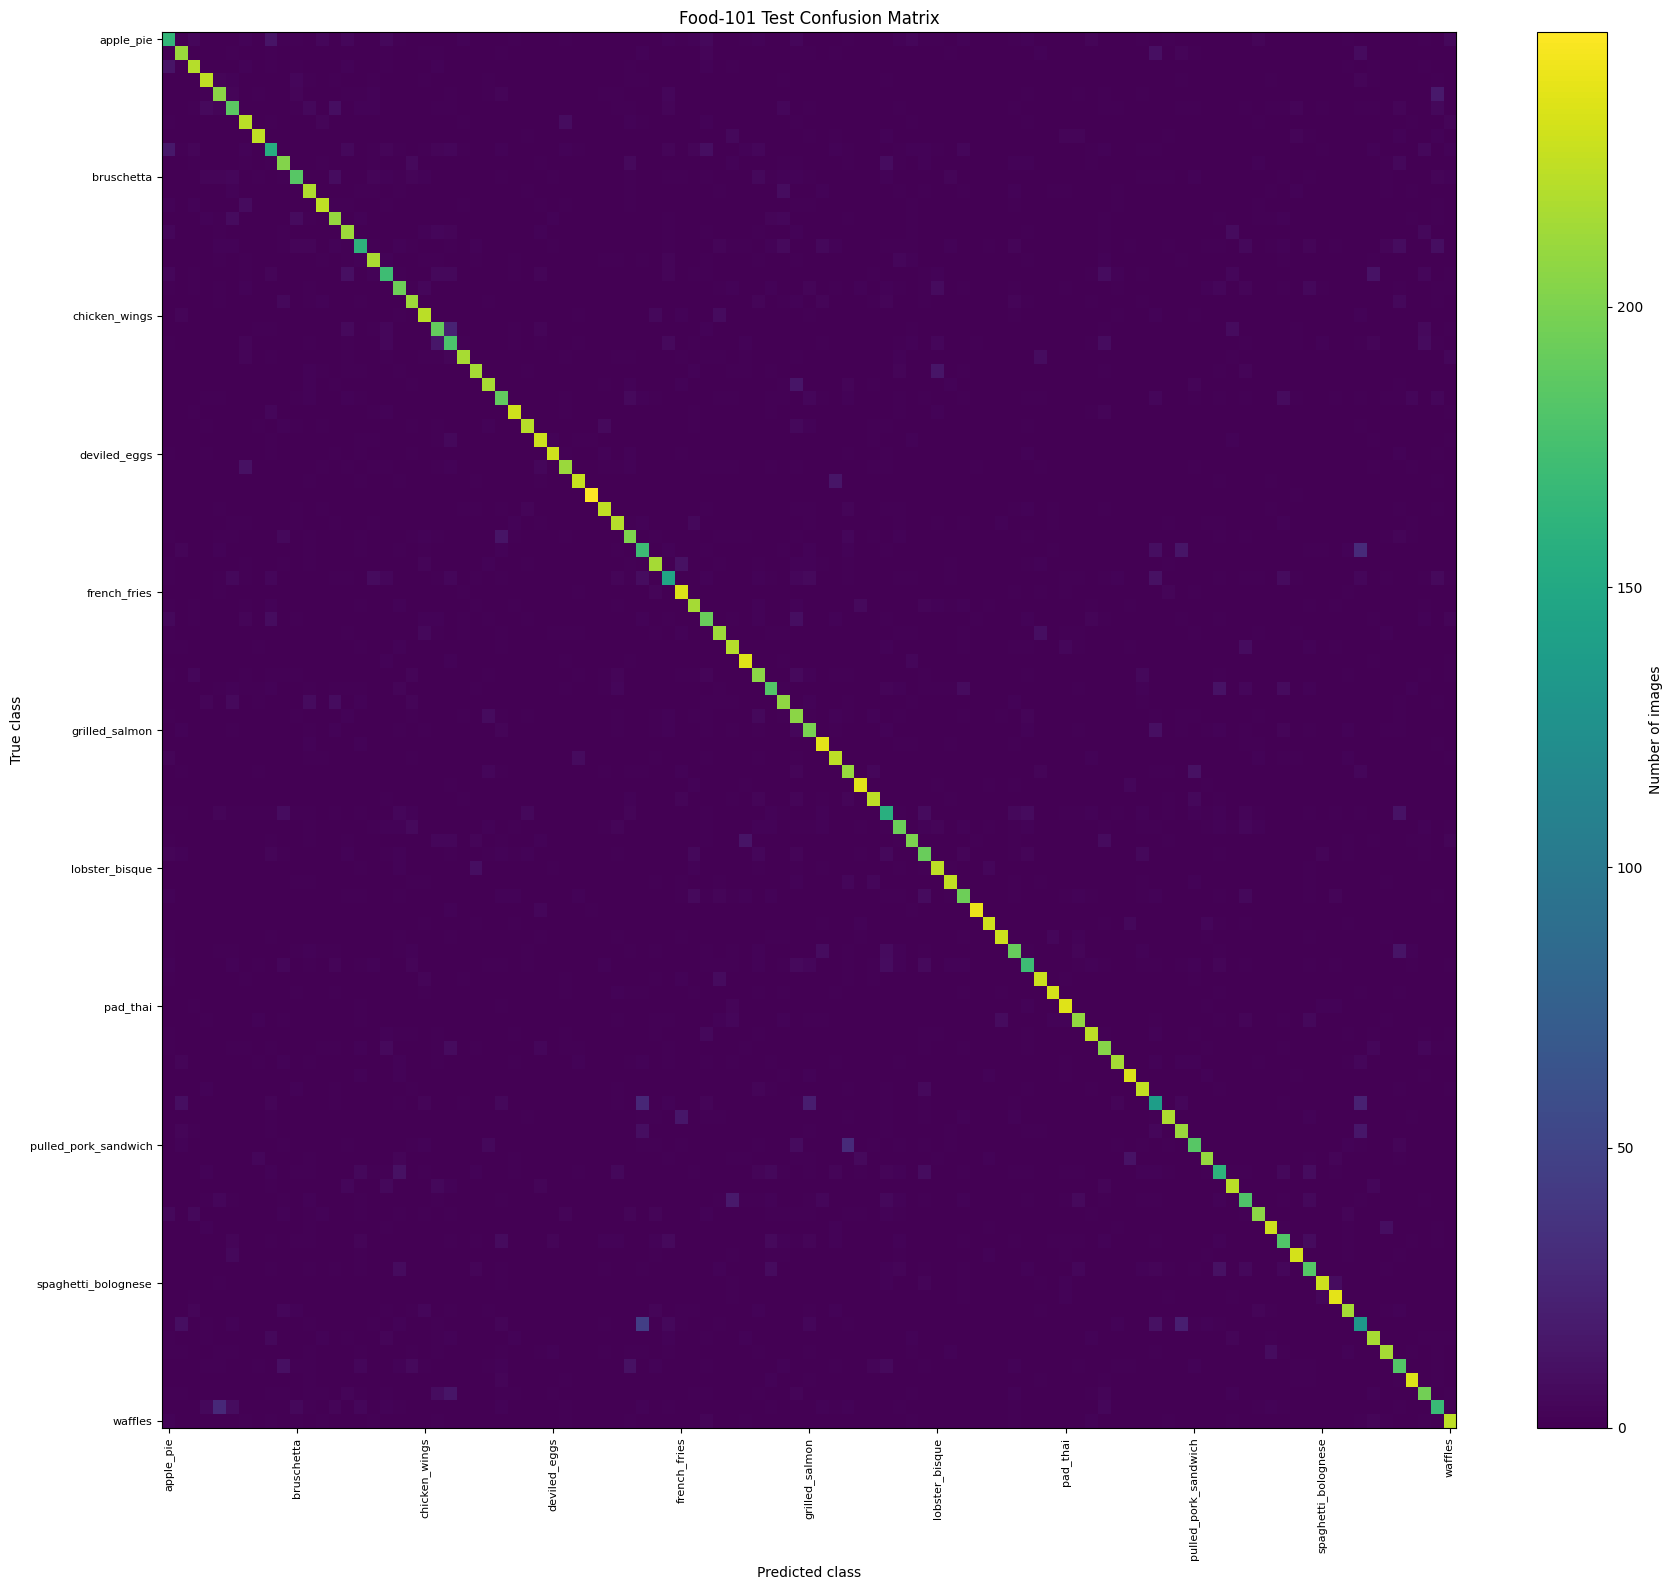

In [19]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(18, 16))
plt.imshow(cm, interpolation="nearest", aspect="auto")
plt.title("Food-101 Test Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
tick_positions = np.arange(0, NUM_CLASSES, 10)
plt.xticks(tick_positions, [class_names[i] for i in tick_positions], rotation=90, fontsize=8)
plt.yticks(tick_positions, [class_names[i] for i in tick_positions], fontsize=8)
plt.colorbar(label="Number of images")
plt.tight_layout()
plt.show()

# 20. Run Sample Predictions

Select a reproducible sample from the test set and compare each predicted label and confidence with its true label.

In [20]:
sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(y_test), size=12, replace=False)
sample_rows = []
for idx in sample_indices:
    confidence = float(test_probs[idx].max())
    pred_id = int(y_pred[idx])
    true_id = int(y_test[idx])
    sample_rows.append({
        "Test index": int(idx),
        "True class": class_names[true_id],
        "Predicted class": class_names[pred_id],
        "Confidence": confidence,
        "Correct": pred_id == true_id
    })
display(pd.DataFrame(sample_rows).round({"Confidence": 4}))

,Test index,True class,Predicted class,Confidence,Correct
0,11078,beet_salad,beet_salad,0.6255,True
1,2169,greek_salad,greek_salad,0.9163,True
2,19534,cheese_plate,cheese_plate,0.9159,True
3,13293,lasagna,lasagna,0.7045,True
4,16522,spaghetti_carbonara,spaghetti_carbonara,0.7051,True
5,21674,waffles,waffles,0.8306,True
6,2252,foie_gras,foie_gras,0.8501,True
7,10930,garlic_bread,baklava,0.4544,False
8,2377,foie_gras,foie_gras,0.6601,True
9,17605,bruschetta,bruschetta,0.5749,True


# 21. Visualize Sample Predictions

Display selected test images with their true labels, predicted labels, and top-class confidence.

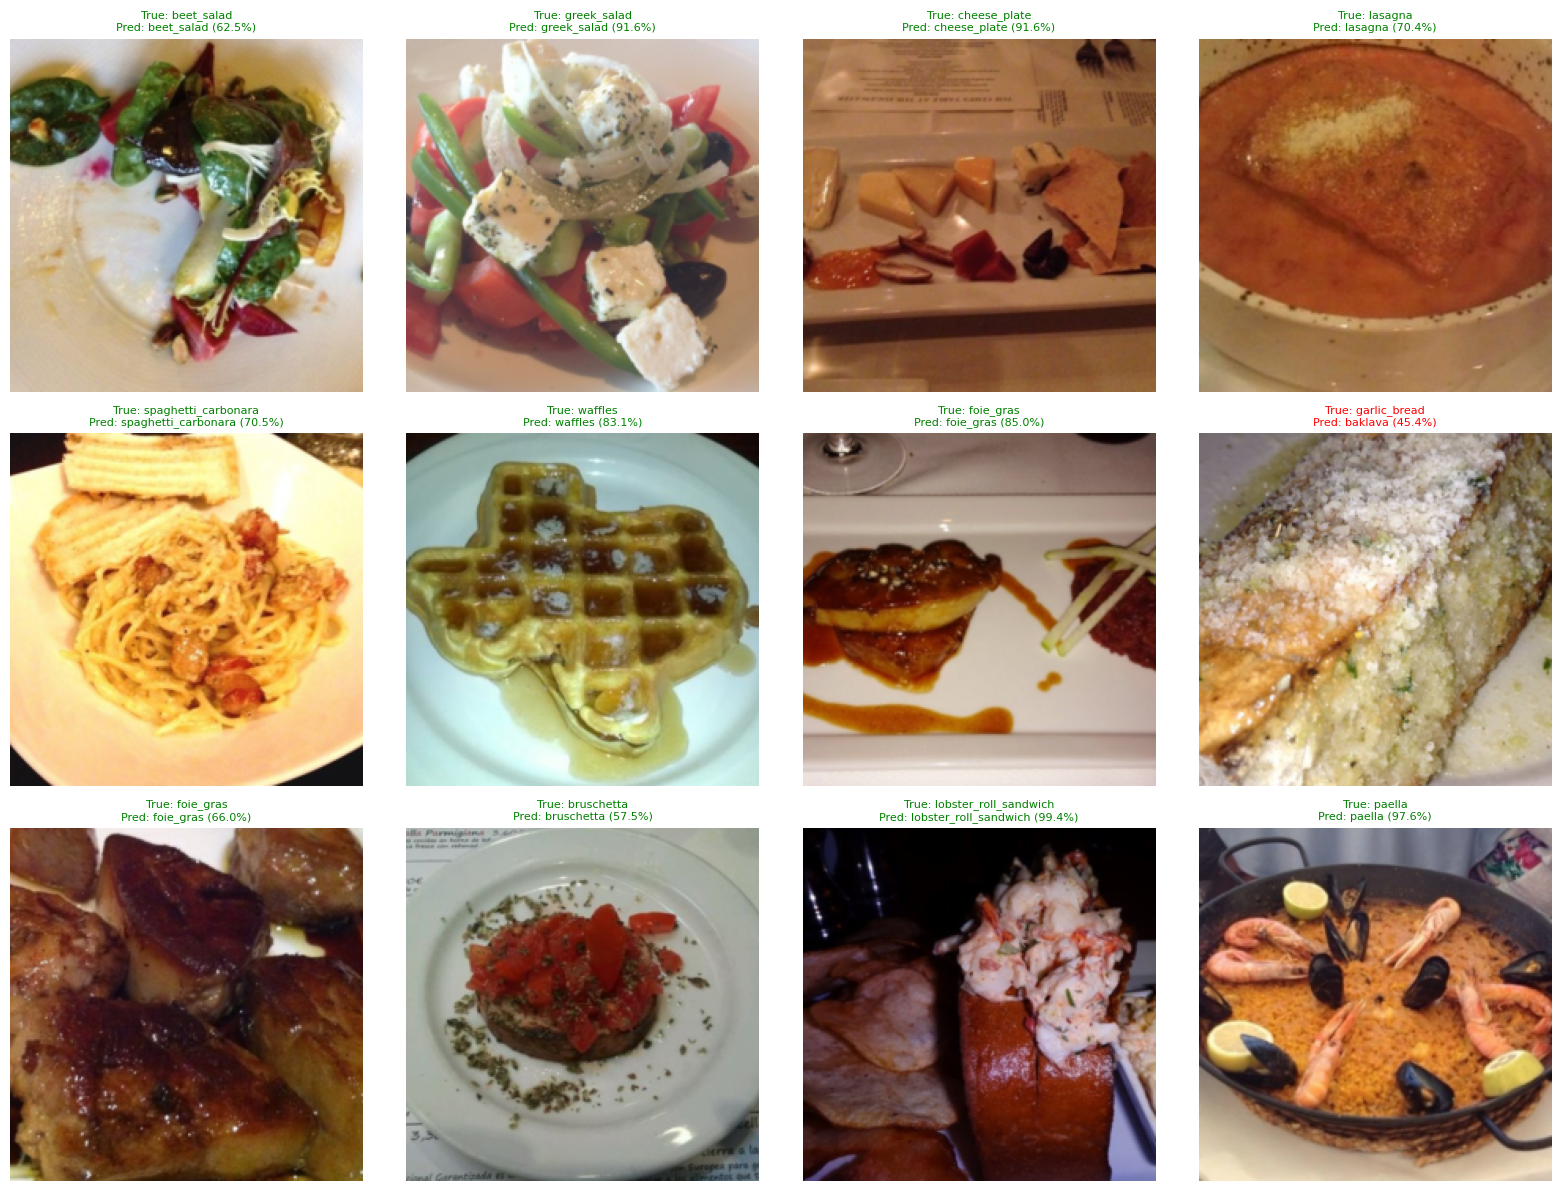

In [21]:
mean_tensor = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(IMAGENET_STD).view(3, 1, 1)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, idx in zip(axes.flat, sample_indices):
    image_tensor, true_id = test_dataset[int(idx)]
    image = (image_tensor * std_tensor + mean_tensor).clamp(0, 1).permute(1, 2, 0).numpy()
    pred_id = int(y_pred[idx])
    confidence = float(test_probs[idx].max())
    ax.imshow(image)
    ax.set_title(
        f"True: {class_names[true_id]}\nPred: {class_names[pred_id]} ({confidence:.1%})",
        color="green" if pred_id == true_id else "red",
        fontsize=8
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

# 22. Inspect Prediction Confidence

Compare confidence for correct and incorrect predictions to understand whether the model's certainty aligns with its accuracy.

,Group,Count,Mean confidence,Median confidence
0,Correct predictions,20968,0.7662,0.8432
1,Incorrect predictions,4282,0.3885,0.3515


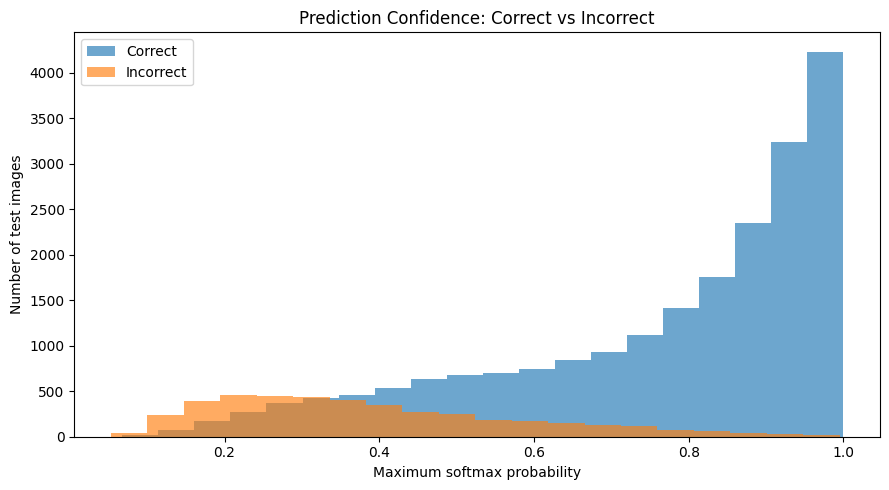

Incorrect predictions with confidence >= 90%: 1.12%


In [22]:
predicted_confidence = test_probs.max(axis=1)
correct_mask = y_pred == y_test
confidence_summary = pd.DataFrame({
    "Group": ["Correct predictions", "Incorrect predictions"],
    "Count": [int(correct_mask.sum()), int((~correct_mask).sum())],
    "Mean confidence": [
        float(predicted_confidence[correct_mask].mean()) if correct_mask.any() else np.nan,
        float(predicted_confidence[~correct_mask].mean()) if (~correct_mask).any() else np.nan
    ],
    "Median confidence": [
        float(np.median(predicted_confidence[correct_mask])) if correct_mask.any() else np.nan,
        float(np.median(predicted_confidence[~correct_mask])) if (~correct_mask).any() else np.nan
    ]
})
display(confidence_summary.round(4))

plt.figure(figsize=(9, 5))
plt.hist(predicted_confidence[correct_mask], bins=20, alpha=0.65, label="Correct")
plt.hist(predicted_confidence[~correct_mask], bins=20, alpha=0.65, label="Incorrect")
plt.xlabel("Maximum softmax probability")
plt.ylabel("Number of test images")
plt.title("Prediction Confidence: Correct vs Incorrect")
plt.legend()
plt.tight_layout()
plt.show()

high_confidence_error_rate = float(np.mean(predicted_confidence[~correct_mask] >= 0.9)) if (~correct_mask).any() else 0.0
print(f"Incorrect predictions with confidence >= 90%: {high_confidence_error_rate:.2%}")

# 23. References and Result Context

Record the dataset, pretrained weights, and public ResNet-50 results that provide context for this experiment.

- [Food-101 dataset — ETH Zürich / Torchvision](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.Food101.html): 101 food categories and 101,000 images, with 750 training and 250 test images per class.
- [ResNet-50 pretrained weights — Torchvision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html): ImageNet-pretrained ResNet-50 weight configurations.
- [Food-101 ResNet-50 public reproduction](https://github.com/tarutak/Food-101-Image-Classification): Reports 87.08% top-1 accuracy using a two-stage ResNet-50 procedure with 224- and 512-pixel image stages and test-time augmentation. That result uses a different recipe and should be treated as a reference, not a guaranteed outcome for this notebook.
- [Food-101 original dataset page](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/): Dataset information from the originating research group.

# 24. Key Findings

# 25. Conclusion